In [60]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')
from pathlib import Path
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from scipy.cluster.hierarchy import linkage, dendrogram
from sklearn.cluster import AgglomerativeClustering
from sklearn.neighbors import NearestNeighbors
from sklearn.cluster import DBSCAN
from sklearn.metrics import davies_bouldin_score, calinski_harabasz_score
import os

In [3]:
base_path = Path().cwd().parent
model_path = base_path/"Model"
data_path = base_path/"Data"/"online_retail_II.csv"

In [5]:
DF = pd.read_csv(data_path)
DF

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,13085.0,United Kingdom
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,13085.0,United Kingdom
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,13085.0,United Kingdom
...,...,...,...,...,...,...,...,...
1067366,581587,22899,CHILDREN'S APRON DOLLY GIRL,6,2011-12-09 12:50:00,2.10,12680.0,France
1067367,581587,23254,CHILDRENS CUTLERY DOLLY GIRL,4,2011-12-09 12:50:00,4.15,12680.0,France
1067368,581587,23255,CHILDRENS CUTLERY CIRCUS PARADE,4,2011-12-09 12:50:00,4.15,12680.0,France
1067369,581587,22138,BAKING SET 9 PIECE RETROSPOT,3,2011-12-09 12:50:00,4.95,12680.0,France


In [10]:
DF.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1067371 entries, 0 to 1067370
Data columns (total 8 columns):
 #   Column       Non-Null Count    Dtype  
---  ------       --------------    -----  
 0   Invoice      1067371 non-null  object 
 1   StockCode    1067371 non-null  object 
 2   Description  1062989 non-null  object 
 3   Quantity     1067371 non-null  int64  
 4   InvoiceDate  1067371 non-null  object 
 5   Price        1067371 non-null  float64
 6   Customer ID  824364 non-null   float64
 7   Country      1067371 non-null  object 
dtypes: float64(2), int64(1), object(5)
memory usage: 65.1+ MB


In [11]:
DF.shape

(1067371, 8)

In [12]:
DF.isnull().sum()

Invoice             0
StockCode           0
Description      4382
Quantity            0
InvoiceDate         0
Price               0
Customer ID    243007
Country             0
dtype: int64

In [13]:
DF.duplicated().sum()

np.int64(34335)

In [14]:
DF.rename(columns={
    'Invoice': 'InvoiceNo',
    'Price': 'UnitPrice',
    'Customer ID': 'CustomerID'
}, inplace=True)

In [15]:
DF.head()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,13085.0,United Kingdom
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,13085.0,United Kingdom
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,13085.0,United Kingdom


In [16]:
DF_all_countries = DF.copy()

In [18]:
DF_UK = DF[DF['Country'] == 'United Kingdom'].copy()
print(f"Rows after filtering to United Kingdom: {DF_UK.shape[0]:,}")

Rows after filtering to United Kingdom: 981,330


In [19]:
DF_UK = DF_UK.dropna(subset=['CustomerID']).copy()
print(f"Rows remaining after dropping null CustomerID: {DF_UK.shape[0]:,}")

Rows remaining after dropping null CustomerID: 741,301


In [21]:
rows_before_qty = DF_UK.shape[0]
DF_UK = DF_UK[DF_UK['Quantity'] > 0].copy()
print(f"Rows dropped (Quantity <= 0): {rows_before_qty - DF_UK.shape[0]:,}")

Rows dropped (Quantity <= 0): 16,005


In [22]:
rows_before_price = DF_UK.shape[0]
DF_UK = DF_UK[DF_UK['UnitPrice'] > 0].copy()
print(f"Rows dropped (UnitPrice <= 0): {rows_before_price - DF_UK.shape[0]:,}")
print(f"Final cleaned rows: {DF_UK.shape[0]:,}")

Rows dropped (UnitPrice <= 0): 46
Final cleaned rows: 725,250


In [24]:
DF_UK['TotalPrice'] = DF_UK['Quantity'] * DF_UK['UnitPrice']
DF_UK['InvoiceDate'] = pd.to_datetime(DF_UK['InvoiceDate'])
DF_UK['CustomerID'] = DF_UK['CustomerID'].astype(int)

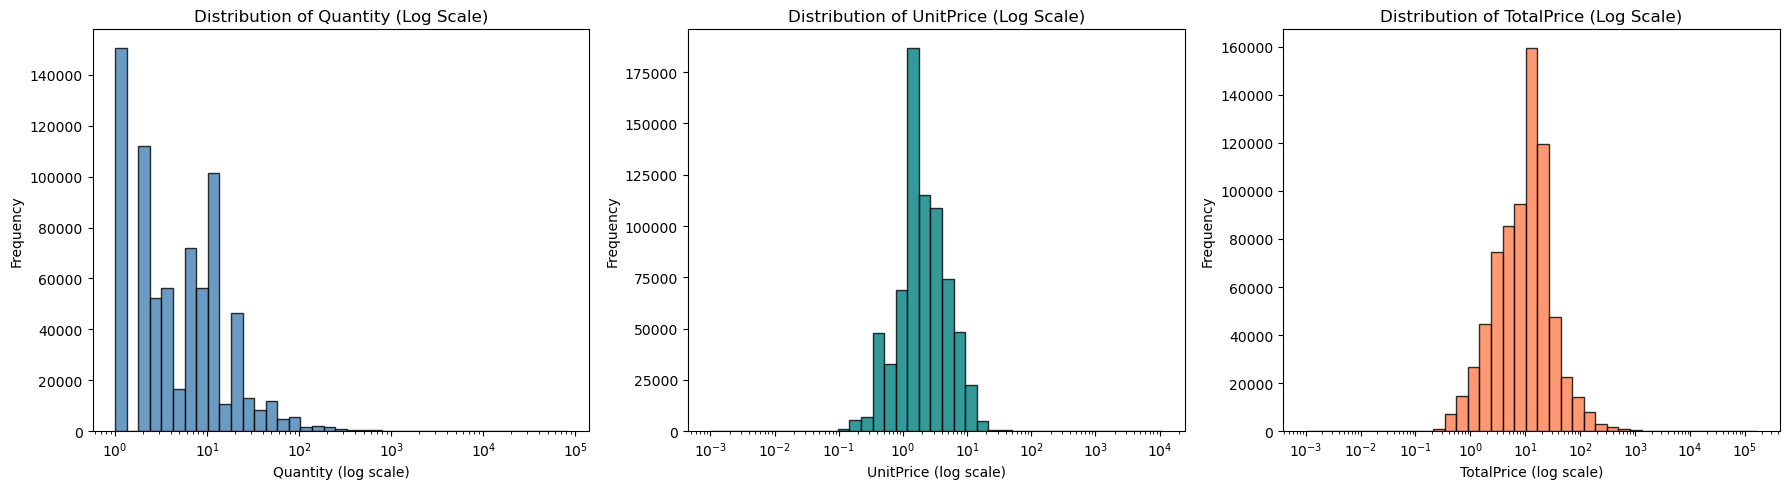

In [26]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for ax, col, color in zip(axes, ['Quantity', 'UnitPrice', 'TotalPrice'], ['steelblue', 'teal', 'coral']):
    log_bins = np.logspace(np.log10(DF_UK[col].min()), np.log10(DF_UK[col].max()), 40)
    ax.hist(DF_UK[col], bins=log_bins, color=color, edgecolor='black', alpha=0.8)
    ax.set_xscale('log')
    ax.set_title(f'Distribution of {col} (Log Scale)')
    ax.set_xlabel(f'{col} (log scale)')
    ax.set_ylabel('Frequency')
plt.tight_layout()
plt.show()

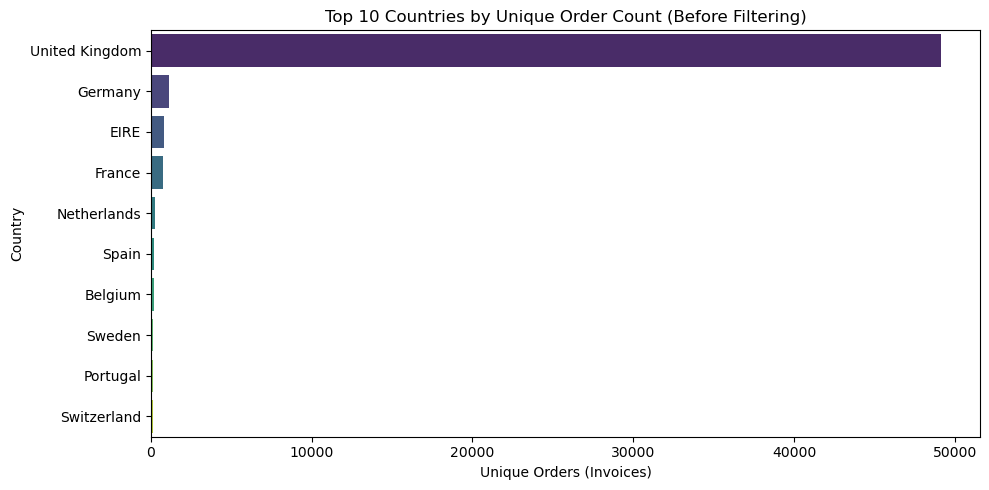

In [27]:
top10_countries = DF_all_countries.groupby('Country')['InvoiceNo'].nunique().sort_values(ascending=False).head(10)
plt.figure(figsize=(10, 5))
sns.barplot(x=top10_countries.values, y=top10_countries.index, palette='viridis')
plt.title('Top 10 Countries by Unique Order Count (Before Filtering)')
plt.xlabel('Unique Orders (Invoices)')
plt.ylabel('Country')
plt.tight_layout()
plt.show()

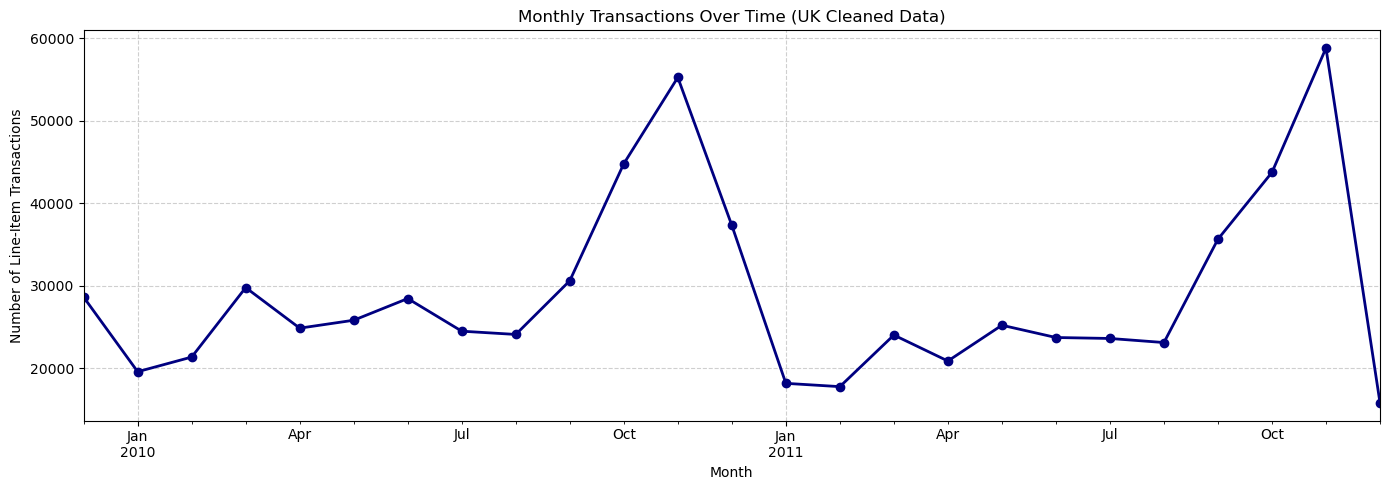

In [28]:
DF_UK['YearMonth'] = DF_UK['InvoiceDate'].dt.to_period('M')
monthly_tx = DF_UK.groupby('YearMonth')['InvoiceNo'].count()

plt.figure(figsize=(14, 5))
monthly_tx.plot(marker='o', color='navy', linewidth=2)
plt.title('Monthly Transactions Over Time (UK Cleaned Data)')
plt.xlabel('Month')
plt.ylabel('Number of Line-Item Transactions')
plt.grid(True, linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()

In [29]:
cust_spend = DF_UK.groupby('CustomerID')['TotalPrice'].sum().sort_values(ascending=False)
cust_orders = DF_UK.groupby('CustomerID')['InvoiceNo'].nunique().sort_values(ascending=False)

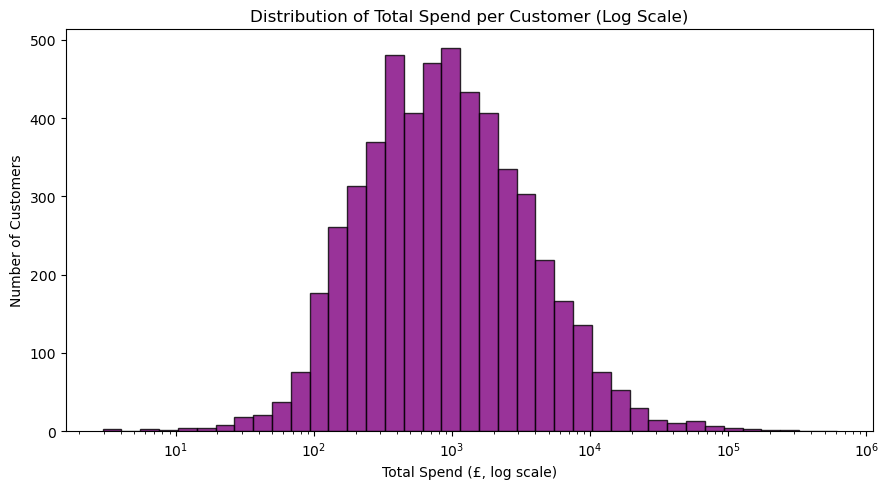

Unique customers remaining after cleaning: 5350

Top 10 Highest-Frequency Buyers (by Unique Invoices):
CustomerID
12748    336
17841    211
15311    208
13089    203
14606    192
17850    155
18102    145
13694    143
15061    127
14527    122
Name: InvoiceNo, dtype: int64


In [32]:
plt.figure(figsize=(9, 5))
log_bins = np.logspace(np.log10(cust_spend.min()), np.log10(cust_spend.max()), 40)
plt.hist(cust_spend, bins=log_bins, color='purple', edgecolor='black', alpha=0.8)
plt.xscale('log')
plt.title('Distribution of Total Spend per Customer (Log Scale)')
plt.xlabel('Total Spend (£, log scale)')
plt.ylabel('Number of Customers')
plt.tight_layout()
plt.show()

print("Unique customers remaining after cleaning:", DF_UK['CustomerID'].nunique())
print("\nTop 10 Highest-Frequency Buyers (by Unique Invoices):")
print(cust_orders.head(10))

In [33]:
cum_revenue_pct = cust_spend.cumsum() / cust_spend.sum()
customers_for_80 = (cum_revenue_pct <= 0.80).sum() + 1
pct_customers_80 = (customers_for_80 / len(cust_spend)) * 100
print(f"\nPareto Result: {customers_for_80:,} out of {len(cust_spend):,} customers ({pct_customers_80:.2f}%) generate 80% of total revenue.")


Pareto Result: 1,301 out of 5,350 customers (24.32%) generate 80% of total revenue.


In [34]:
reference_date = pd.Timestamp('2011-12-31')

rfm_df = DF_UK.groupby('CustomerID').agg(
    Recency=('InvoiceDate', lambda x: (reference_date - x.max()).days),
    Frequency=('InvoiceNo', 'nunique'),
    Monetary=('TotalPrice', 'sum')
).reset_index()

display(rfm_df.head(10))
print("\nSummary Statistics (.describe()):")
display(rfm_df[['Recency', 'Frequency', 'Monetary']].describe())
print("\nSkewness before preprocessing:")
print(rfm_df[['Recency', 'Frequency', 'Monetary']].skew())

,CustomerID,Recency,Frequency,Monetary
0,12346,346,12,77556.46
1,12608,425,1,415.79
2,12745,507,2,723.85
3,12746,561,1,254.55
4,12747,23,26,9276.54
5,12748,21,336,56599.39
6,12749,24,9,6897.36
7,12777,478,1,519.45
8,12819,479,1,540.52
9,12820,24,11,2689.52



Summary Statistics (.describe()):


,Recency,Frequency,Monetary
count,5350.000000,5350.000000,5350.000000
mean,223.546168,6.269346,2751.990190
std,209.973818,11.995550,12080.466564
min,21.000000,1.000000,2.950000
25%,46.000000,1.000000,336.167500
50%,119.000000,3.000000,849.910000
75%,402.000000,7.000000,2214.905000
max,759.000000,336.000000,608821.650000



Skewness before preprocessing:
Recency       0.871993
Frequency    10.433090
Monetary     28.971352
dtype: float64


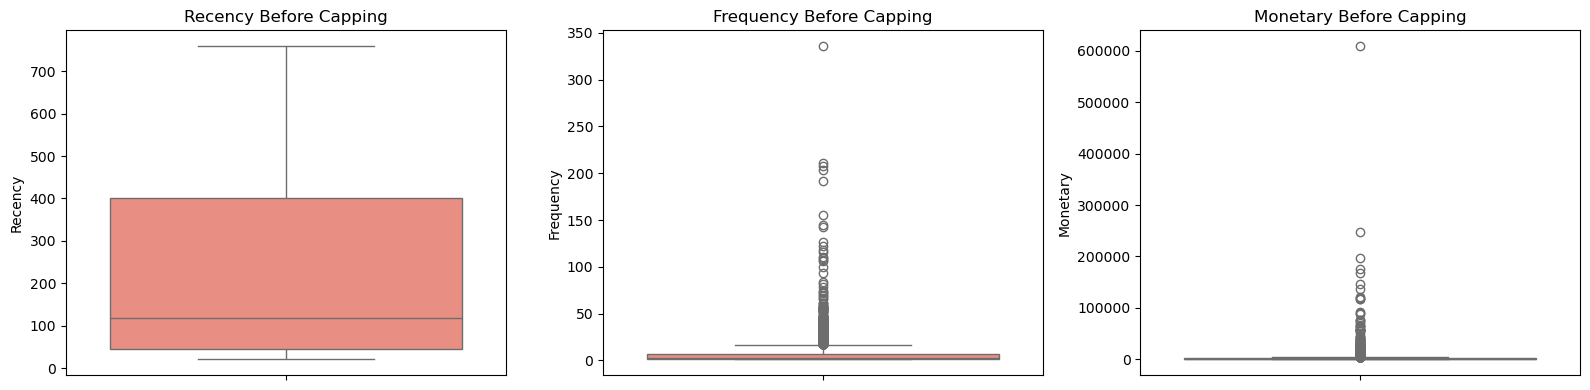

Recency: Q3 + 3*IQR Cap = 1470.00
Frequency: Q3 + 3*IQR Cap = 25.00
Monetary: Q3 + 3*IQR Cap = 7851.12


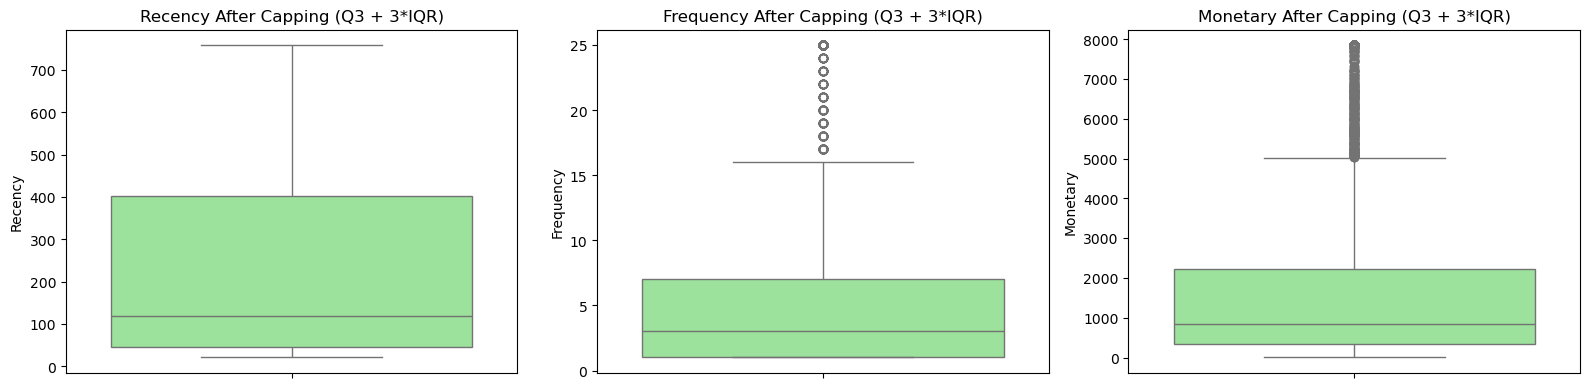

In [35]:
# Boxplots BEFORE capping
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, col in zip(axes, ['Recency', 'Frequency', 'Monetary']):
    sns.boxplot(y=rfm_df[col], ax=ax, color='salmon')
    ax.set_title(f'{col} Before Capping')
plt.tight_layout()
plt.show()

# Cap values above Q3 + 3 * IQR
rfm_capped = rfm_df.copy()
for col in ['Recency', 'Frequency', 'Monetary']:
    Q1 = rfm_capped[col].quantile(0.25)
    Q3 = rfm_capped[col].quantile(0.75)
    IQR = Q3 - Q1
    upper_cap = Q3 + 3 * IQR
    rfm_capped[col] = np.where(rfm_capped[col] > upper_cap, upper_cap, rfm_capped[col])
    print(f"{col}: Q3 + 3*IQR Cap = {upper_cap:.2f}")

# Boxplots AFTER capping
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, col in zip(axes, ['Recency', 'Frequency', 'Monetary']):
    sns.boxplot(y=rfm_capped[col], ax=ax, color='lightgreen')
    ax.set_title(f'{col} After Capping (Q3 + 3*IQR)')
plt.tight_layout()
plt.show()

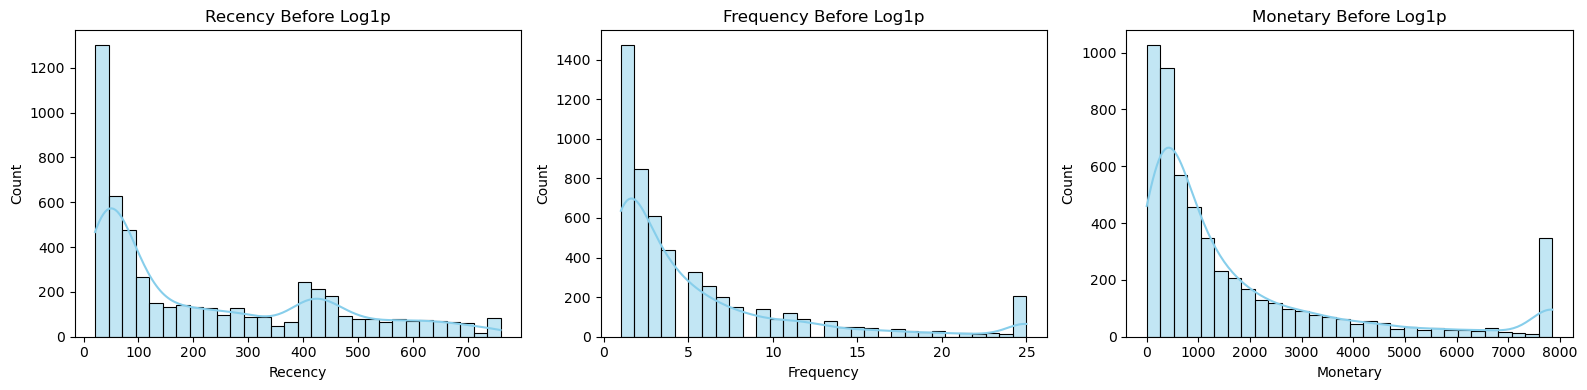

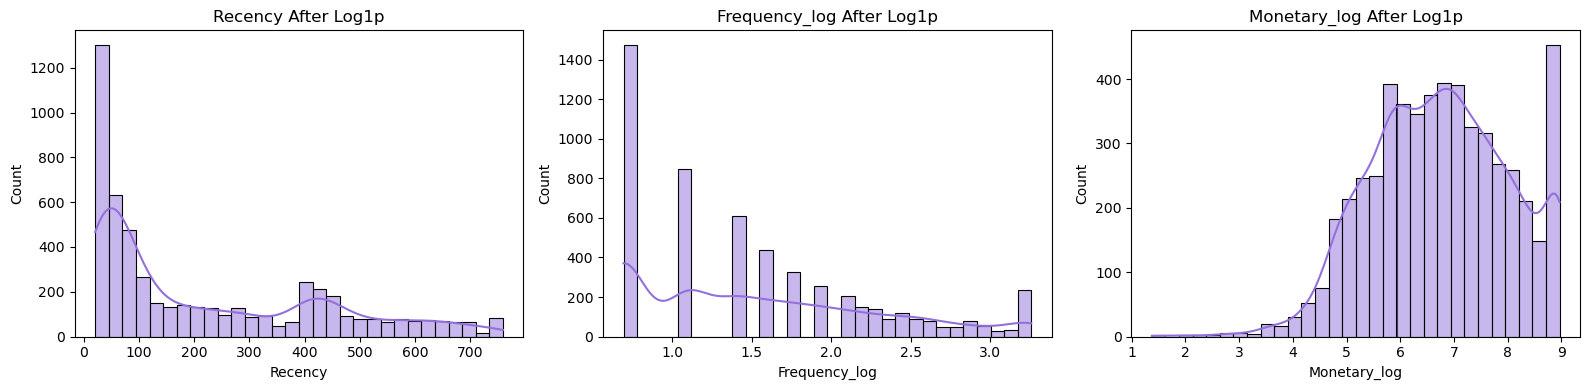

Skewness after log1p:
Recency          0.871993
Frequency_log    0.636539
Monetary_log    -0.135644
dtype: float64


In [36]:
# Histograms BEFORE log1p transformation
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, col in zip(axes, ['Recency', 'Frequency', 'Monetary']):
    sns.histplot(rfm_capped[col], bins=30, kde=True, ax=ax, color='skyblue')
    ax.set_title(f'{col} Before Log1p')
plt.tight_layout()
plt.show()

# Apply log1p to Frequency and Monetary
rfm_trans = rfm_capped.copy()
rfm_trans['Frequency_log'] = np.log1p(rfm_trans['Frequency'])
rfm_trans['Monetary_log'] = np.log1p(rfm_trans['Monetary'])

# Histograms AFTER log1p transformation
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, col in zip(axes, ['Recency', 'Frequency_log', 'Monetary_log']):
    sns.histplot(rfm_trans[col], bins=30, kde=True, ax=ax, color='mediumpurple')
    ax.set_title(f'{col} After Log1p')
plt.tight_layout()
plt.show()

print("Skewness after log1p:")
print(rfm_trans[['Recency', 'Frequency_log', 'Monetary_log']].skew())

In [38]:
features = ['Recency', 'Frequency_log', 'Monetary_log']
scaler = StandardScaler()
rfm_scaled_arr = scaler.fit_transform(rfm_trans[features])
rfm_scaled = pd.DataFrame(rfm_scaled_arr, columns=features)

print("Mean of scaled features:\n", rfm_scaled.mean().round(4))
print("\nStandard deviation of scaled features:\n", rfm_scaled.std().round(4))

Mean of scaled features:
 Recency         -0.0
Frequency_log    0.0
Monetary_log     0.0
dtype: float64

Standard deviation of scaled features:
 Recency          1.0001
Frequency_log    1.0001
Monetary_log     1.0001
dtype: float64


  File "d:\Users\mantr\anaconda3\Lib\site-packages\joblib\externals\loky\backend\context.py", line 257, in _count_physical_cores
    cpu_info = subprocess.run(
        "wmic CPU Get NumberOfCores /Format:csv".split(),
        capture_output=True,
        text=True,
    )
  File "d:\Users\mantr\anaconda3\Lib\subprocess.py", line 554, in run
    with Popen(*popenargs, **kwargs) as process:
         ~~~~~^^^^^^^^^^^^^^^^^^^^^^
  File "d:\Users\mantr\anaconda3\Lib\subprocess.py", line 1039, in __init__
    self._execute_child(args, executable, preexec_fn, close_fds,
    ~~~~~~~~~~~~~~~~~~~^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
                        pass_fds, cwd, env,
                        ^^^^^^^^^^^^^^^^^^^
    ...<5 lines>...
                        gid, gids, uid, umask,
                        ^^^^^^^^^^^^^^^^^^^^^^
                        start_new_session, process_group)
                        ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "d:\Users\mantr\anaconda3\Lib\subprocess.

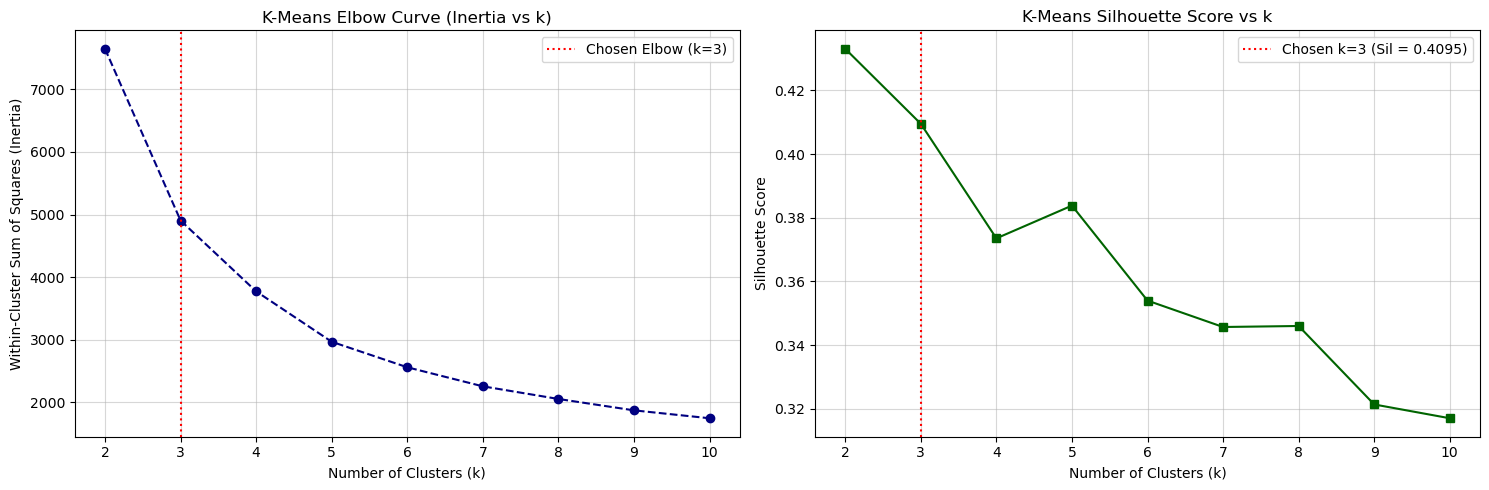

k= 2 | Inertia:  7644.71 | Silhouette Score: 0.4331
k= 3 | Inertia:  4903.89 | Silhouette Score: 0.4095
k= 4 | Inertia:  3773.79 | Silhouette Score: 0.3735
k= 5 | Inertia:  2969.21 | Silhouette Score: 0.3838
k= 6 | Inertia:  2562.20 | Silhouette Score: 0.3540
k= 7 | Inertia:  2258.05 | Silhouette Score: 0.3457
k= 8 | Inertia:  2056.31 | Silhouette Score: 0.3460
k= 9 | Inertia:  1874.77 | Silhouette Score: 0.3213
k=10 | Inertia:  1748.59 | Silhouette Score: 0.3170


In [40]:
inertias = []
sil_scores = []
k_values = range(2, 11)

for k in k_values:
    km = KMeans(n_clusters=k, init='k-means++', n_init=10, random_state=42)
    labels = km.fit_predict(rfm_scaled)
    inertias.append(km.inertia_)
    sil_scores.append(silhouette_score(rfm_scaled, labels))

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Elbow Plot
axes[0].plot(k_values, inertias, marker='o', linestyle='--', color='navy')
axes[0].axvline(x=3, color='red', linestyle=':', label='Chosen Elbow (k=3)')
axes[0].set_title('K-Means Elbow Curve (Inertia vs k)')
axes[0].set_xlabel('Number of Clusters (k)')
axes[0].set_ylabel('Within-Cluster Sum of Squares (Inertia)')
axes[0].legend()
axes[0].grid(True, alpha=0.5)

# Silhouette Plot
axes[1].plot(k_values, sil_scores, marker='s', linestyle='-', color='darkgreen')
axes[1].axvline(x=3, color='red', linestyle=':', label='Chosen k=3 (Sil = 0.4095)')
axes[1].set_title('K-Means Silhouette Score vs k')
axes[1].set_xlabel('Number of Clusters (k)')
axes[1].set_ylabel('Silhouette Score')
axes[1].legend()
axes[1].grid(True, alpha=0.5)

plt.tight_layout()
plt.show()

for k, iner, sil in zip(k_values, inertias, sil_scores):
    print(f"k={k:2d} | Inertia: {iner:8.2f} | Silhouette Score: {sil:.4f}")

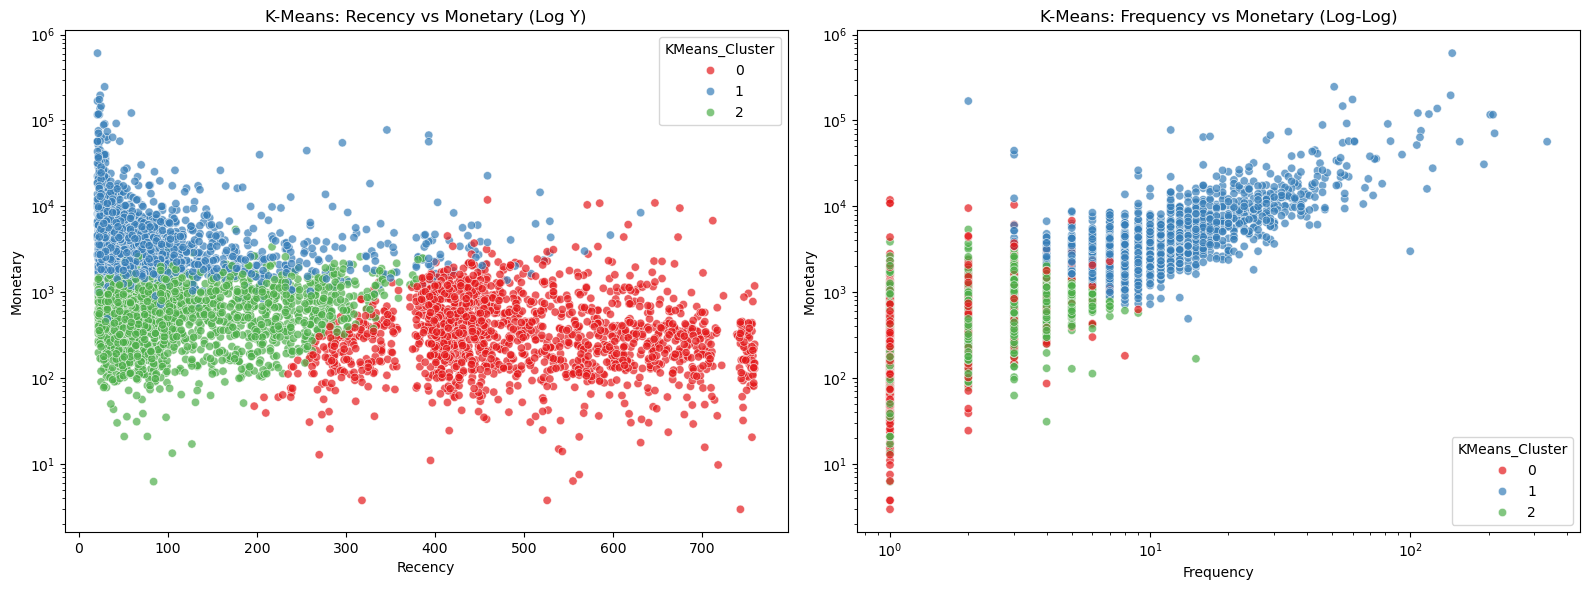

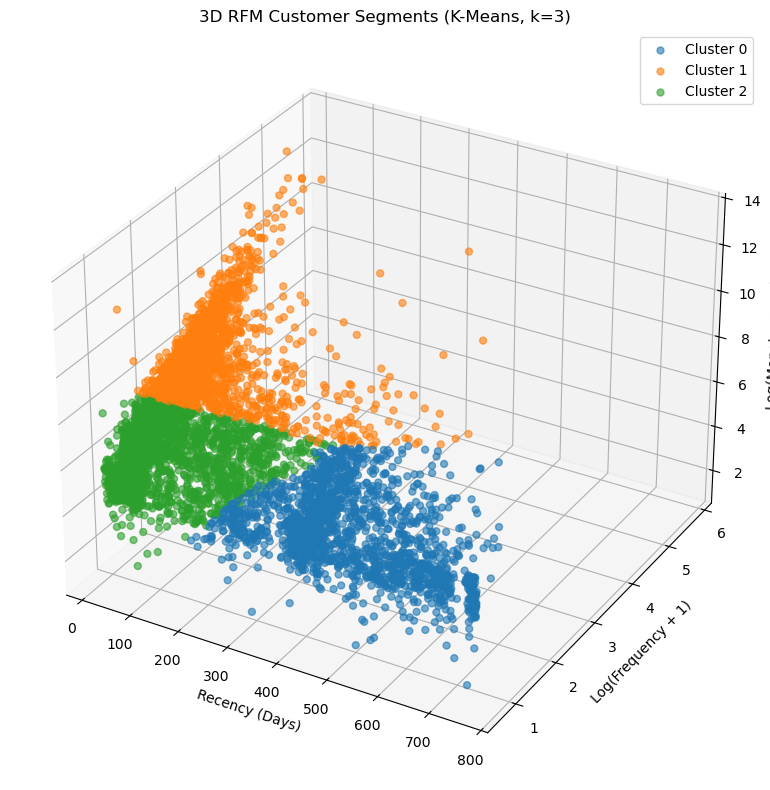

In [41]:
k_optimal = 3
kmeans_final = KMeans(n_clusters=k_optimal, init='k-means++', n_init=20, max_iter=500, random_state=42)
rfm_df['KMeans_Cluster'] = kmeans_final.fit_predict(rfm_scaled)

# 2D Scatter Plots: Recency vs Monetary & Frequency vs Monetary
fig, axes = plt.subplots(1, 2, figsize=(16, 6))
sns.scatterplot(data=rfm_df, x='Recency', y='Monetary', hue='KMeans_Cluster', palette='Set1', alpha=0.7, ax=axes[0])
axes[0].set_yscale('log')
axes[0].set_title('K-Means: Recency vs Monetary (Log Y)')

sns.scatterplot(data=rfm_df, x='Frequency', y='Monetary', hue='KMeans_Cluster', palette='Set1', alpha=0.7, ax=axes[1])
axes[1].set_xscale('log')
axes[1].set_yscale('log')
axes[1].set_title('K-Means: Frequency vs Monetary (Log-Log)')
plt.tight_layout()
plt.show()

# 3D Scatter Plot
from mpl_toolkits.mplot3d import Axes3D
fig = plt.figure(figsize=(10, 8))
ax = fig.add_subplot(111, projection='3d')
for c in sorted(rfm_df['KMeans_Cluster'].unique()):
    sub = rfm_df[rfm_df['KMeans_Cluster'] == c]
    ax.scatter(sub['Recency'], np.log1p(sub['Frequency']), np.log1p(sub['Monetary']), label=f'Cluster {c}', alpha=0.6, s=25)
ax.set_xlabel('Recency (Days)')
ax.set_ylabel('Log(Frequency + 1)')
ax.set_zlabel('Log(Monetary + 1)')
ax.set_title('3D RFM Customer Segments (K-Means, k=3)')
ax.legend()
plt.tight_layout()
plt.show()

In [42]:
km_profile = rfm_df.groupby('KMeans_Cluster').agg(
    Customer_Count=('CustomerID', 'count'),
    Mean_Recency=('Recency', 'mean'),
    Mean_Frequency=('Frequency', 'mean'),
    Mean_Monetary=('Monetary', 'mean')
).sort_values(by='Mean_Monetary', ascending=False)

persona_map = {
    1: 'Champions (VIP Loyalists)',
    2: 'Loyal / Potential Loyalists',
    0: 'Hibernating / Churned'
}
km_profile['Persona'] = km_profile.index.map(persona_map)
display(km_profile.round(2))

,Customer_Count,Mean_Recency,Mean_Frequency,Mean_Monetary,Persona
KMeans_Cluster,,,,,
1,1733,86.15,14.63,7164.94,Champions (VIP Loyalists)
2,1949,112.90,2.69,736.07,Loyal / Potential Loyalists
0,1668,495.58,1.77,522.60,Hibernating / Churned


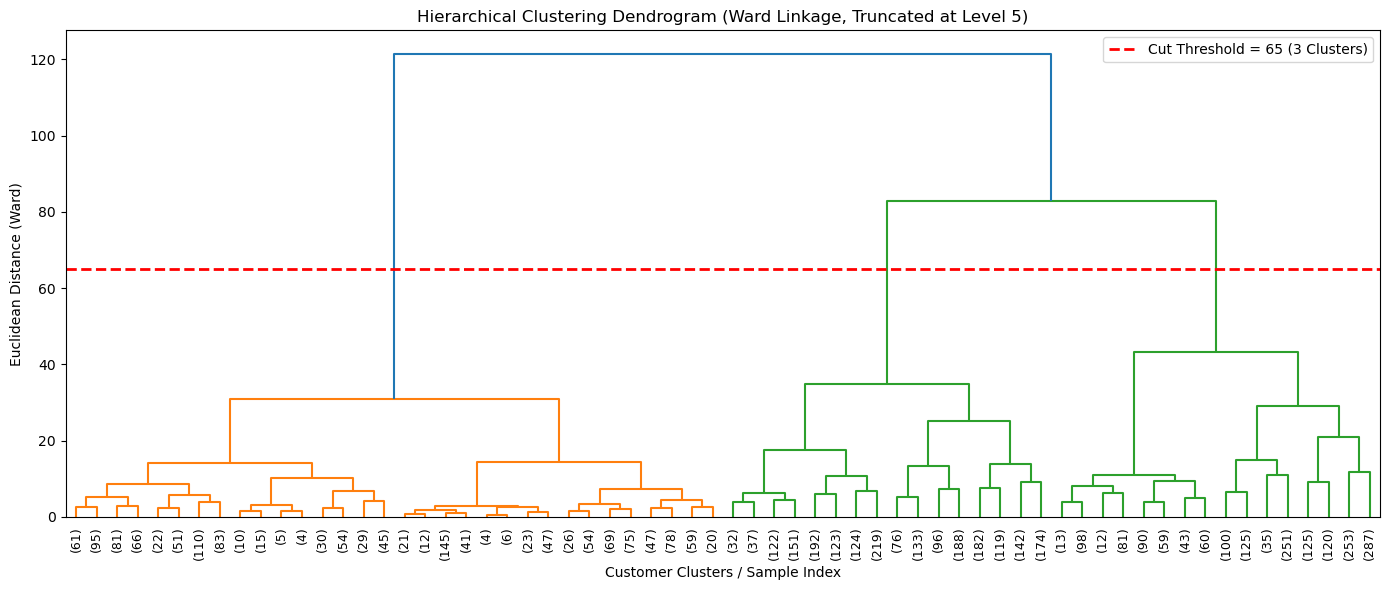

In [44]:
Z = linkage(rfm_scaled, method='ward')

plt.figure(figsize=(14, 6))
dendrogram(Z, truncate_mode='level', p=5, leaf_rotation=90., leaf_font_size=9.)
plt.axhline(y=65, color='red', linestyle='--', linewidth=2, label='Cut Threshold = 65 (3 Clusters)')
plt.title('Hierarchical Clustering Dendrogram (Ward Linkage, Truncated at Level 5)')
plt.xlabel('Customer Clusters / Sample Index')
plt.ylabel('Euclidean Distance (Ward)')
plt.legend()
plt.tight_layout()
plt.show()

In [45]:
for link in ['ward', 'complete', 'average']:
    agg = AgglomerativeClustering(n_clusters=3, linkage=link)
    lbls = agg.fit_predict(rfm_scaled)
    sil = silhouette_score(rfm_scaled, lbls)
    print(f"Linkage: {link:8s} | Silhouette Score: {sil:.4f} | Cluster Sizes: {np.bincount(lbls)}")

# Best linkage is 'ward'
agg_best = AgglomerativeClustering(n_clusters=3, linkage='ward')
rfm_df['Agg_Cluster'] = agg_best.fit_predict(rfm_scaled)

Linkage: ward     | Silhouette Score: 0.3859 | Cluster Sizes: [1752 1488 2110]
Linkage: complete | Silhouette Score: 0.3265 | Cluster Sizes: [ 658 3514 1178]
Linkage: average  | Silhouette Score: 0.3213 | Cluster Sizes: [4222    7 1121]


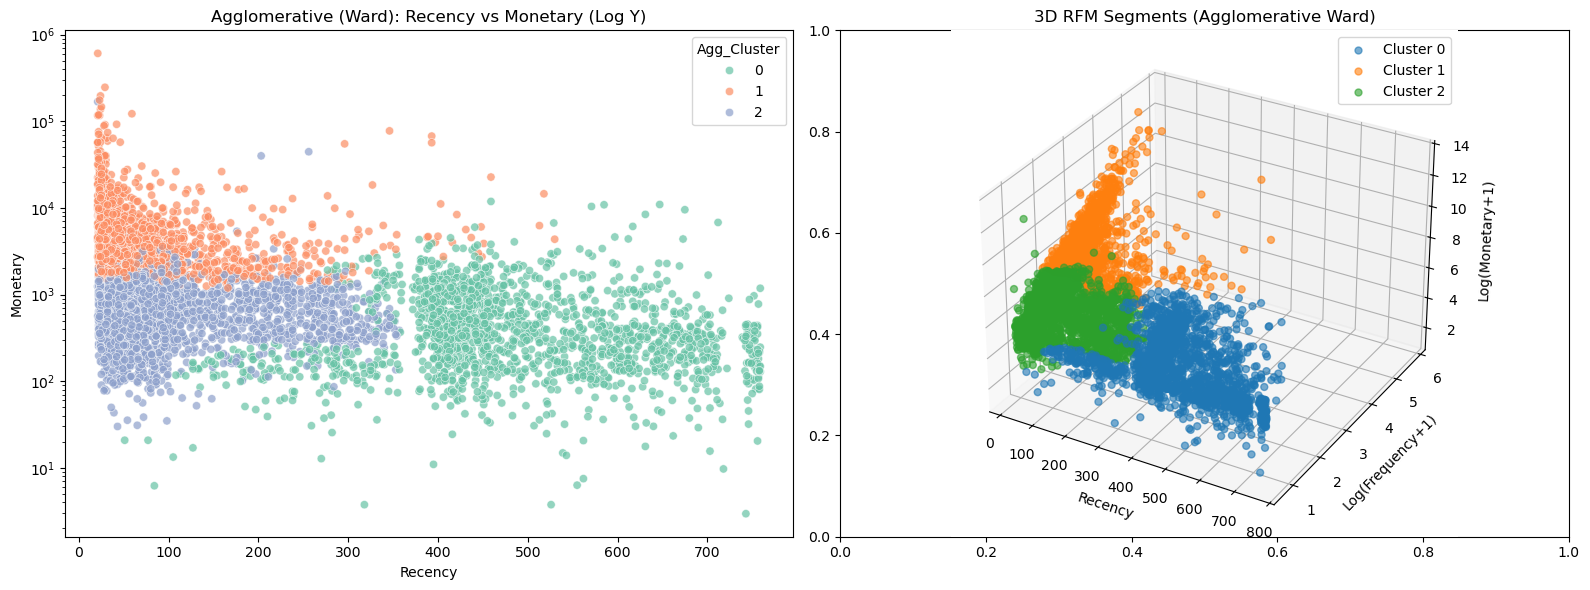

,Customer_Count,Mean_Recency,Mean_Frequency,Mean_Monetary,Persona
Agg_Cluster,,,,,
1,1488,77.81,15.98,7858.85,Champions
2,2110,109.34,2.99,935.08,Loyal / Potential Loyalists
0,1752,484.86,1.97,602.84,Hibernating / Churned


In [46]:
# 2D & 3D Scatter Plots
fig, axes = plt.subplots(1, 2, figsize=(16, 6))
sns.scatterplot(data=rfm_df, x='Recency', y='Monetary', hue='Agg_Cluster', palette='Set2', alpha=0.7, ax=axes[0])
axes[0].set_yscale('log')
axes[0].set_title('Agglomerative (Ward): Recency vs Monetary (Log Y)')

ax3d = fig.add_subplot(1, 2, 2, projection='3d')
for c in sorted(rfm_df['Agg_Cluster'].unique()):
    sub = rfm_df[rfm_df['Agg_Cluster'] == c]
    ax3d.scatter(sub['Recency'], np.log1p(sub['Frequency']), np.log1p(sub['Monetary']), label=f'Cluster {c}', alpha=0.6, s=25)
ax3d.set_xlabel('Recency')
ax3d.set_ylabel('Log(Frequency+1)')
ax3d.set_zlabel('Log(Monetary+1)')
ax3d.set_title('3D RFM Segments (Agglomerative Ward)')
ax3d.legend()
plt.tight_layout()
plt.show()

agg_profile = rfm_df.groupby('Agg_Cluster').agg(
    Customer_Count=('CustomerID', 'count'),
    Mean_Recency=('Recency', 'mean'),
    Mean_Frequency=('Frequency', 'mean'),
    Mean_Monetary=('Monetary', 'mean')
).sort_values(by='Mean_Monetary', ascending=False)
agg_profile['Persona'] = agg_profile.index.map({1: 'Champions', 2: 'Loyal / Potential Loyalists', 0: 'Hibernating / Churned'})
display(agg_profile.round(2))

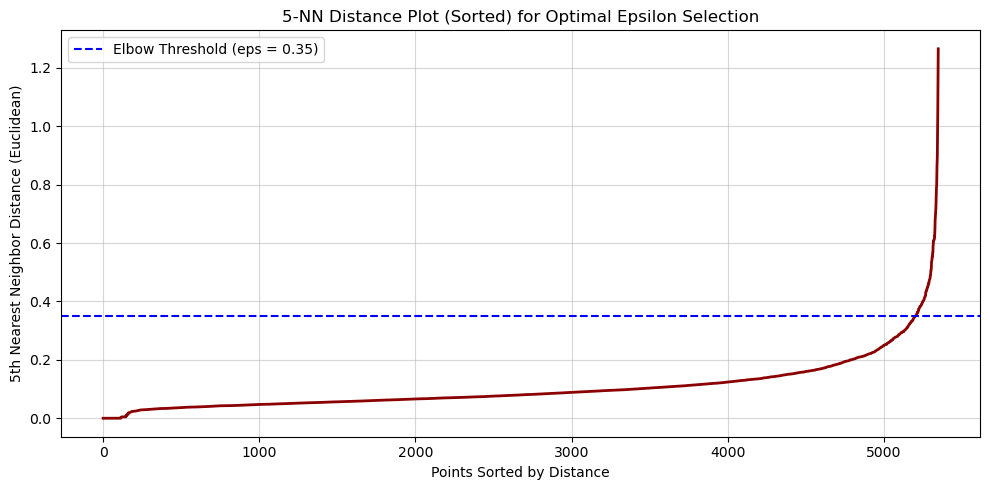

In [48]:
nn = NearestNeighbors(n_neighbors=5)
nn.fit(rfm_scaled)
distances, _ = nn.kneighbors(rfm_scaled)
k_distances = np.sort(distances[:, 4])

plt.figure(figsize=(10, 5))
plt.plot(k_distances, color='darkred', linewidth=2)
plt.axhline(y=0.35, color='blue', linestyle='--', label='Elbow Threshold (eps = 0.35)')
plt.title('5-NN Distance Plot (Sorted) for Optimal Epsilon Selection')
plt.xlabel('Points Sorted by Distance')
plt.ylabel('5th Nearest Neighbor Distance (Euclidean)')
plt.legend()
plt.grid(True, alpha=0.5)
plt.tight_layout()
plt.show()

In [49]:
db_init = DBSCAN(eps=0.35, min_samples=5, metric='euclidean')
init_labels = db_init.fit_predict(rfm_scaled)

n_clusters_init = len(set(init_labels)) - (1 if -1 in init_labels else 0)
n_noise_init = list(init_labels).count(-1)
pct_noise_init = (n_noise_init / len(init_labels)) * 100

print(f"Clusters found (excluding noise): {n_clusters_init}")
print(f"Noise points: {n_noise_init} ({pct_noise_init:.2f}% of customers)")

Clusters found (excluding noise): 3
Noise points: 85 (1.59% of customers)


,eps,min_samples,n_clusters,noise_pct,silhouette
0,0.3,3,7,1.61,0.005152
1,0.3,5,5,2.43,0.105491
2,0.3,8,3,3.63,0.198689
3,0.3,10,3,4.41,0.201054
4,0.5,3,3,0.32,0.304084
5,0.5,5,2,0.49,0.333463
6,0.5,8,2,0.73,0.333440
7,0.5,10,2,0.77,0.333265
8,0.7,3,1,0.07,NaN
9,0.7,5,1,0.11,NaN


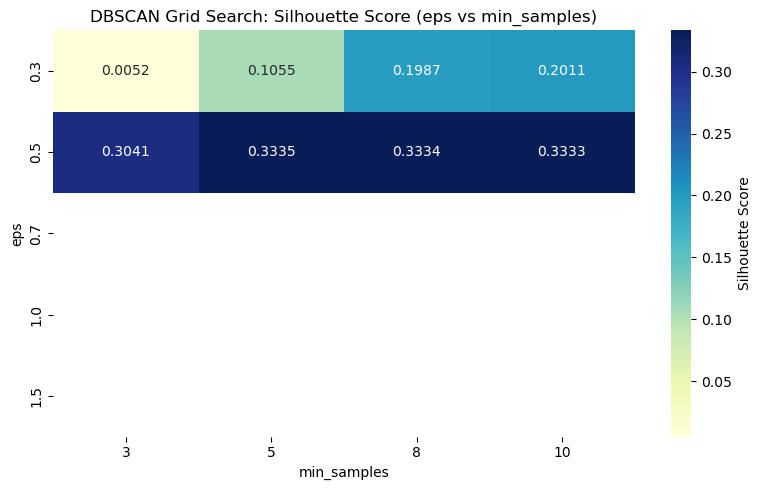

In [51]:
eps_list = [0.3, 0.5, 0.7, 1.0, 1.5]
ms_list = [3, 5, 8, 10]
grid_results = []

for eps in eps_list:
    for ms in ms_list:
        db = DBSCAN(eps=eps, min_samples=ms, metric='euclidean')
        lbls = db.fit_predict(rfm_scaled)
        n_clust = len(set(lbls)) - (1 if -1 in lbls else 0)
        n_noise = list(lbls).count(-1)
        mask = lbls != -1
        sil = silhouette_score(rfm_scaled[mask], lbls[mask]) if (n_clust >= 2 and mask.sum() > 0) else np.nan
        grid_results.append({
            'eps': eps, 'min_samples': ms, 'n_clusters': n_clust,
            'noise_pct': round(n_noise / len(lbls) * 100, 2),
            'silhouette': sil
        })

grid_df = pd.DataFrame(grid_results)
display(grid_df)

pivot_sil = grid_df.pivot(index='eps', columns='min_samples', values='silhouette')
plt.figure(figsize=(8, 5))
sns.heatmap(pivot_sil, annot=True, fmt='.4f', cmap='YlGnBu', cbar_kws={'label': 'Silhouette Score'})
plt.title('DBSCAN Grid Search: Silhouette Score (eps vs min_samples)')
plt.tight_layout()
plt.show()

# Best combination: eps=0.5, min_samples=5 (Silhouette = 0.3335, 2 clusters, 0.49% noise)
db_best = DBSCAN(eps=0.5, min_samples=5, metric='euclidean')
rfm_df['DBSCAN_Cluster'] = db_best.fit_predict(rfm_scaled)

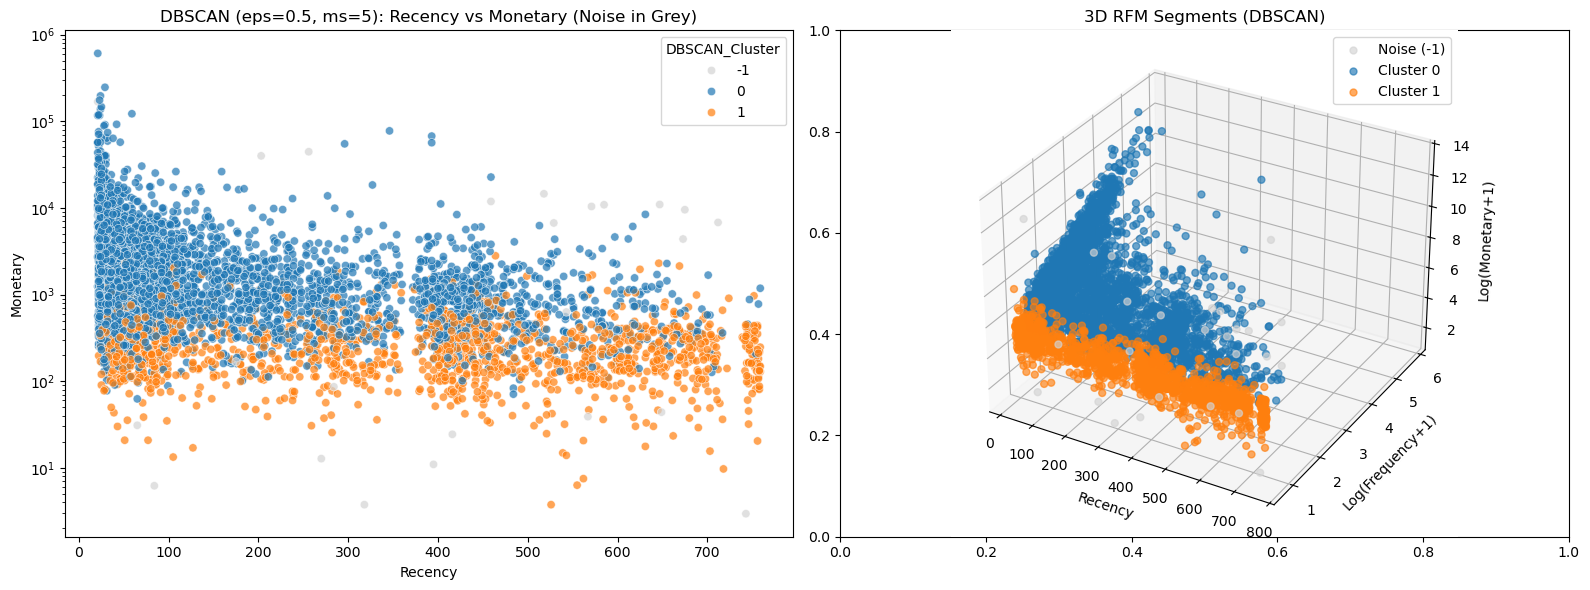

,Customer_Count,Mean_Recency,Mean_Frequency,Mean_Monetary,Persona
DBSCAN_Cluster,,,,,
0,3859,163.05,8.28,3612.21,Multi-Purchase Active Base (Cluster 0)
1,1465,378.87,1.00,302.38,One-Time / Lapsed Buyers (Cluster 1)



Noise (-1) Profile:


,Recency,Frequency,Monetary
count,26.00,26.00,26.00
mean,450.04,4.96,13102.40
std,220.89,8.97,33703.01
min,21.00,1.00,2.95
25%,273.50,1.00,32.94
50%,523.50,2.00,528.88
75%,648.50,4.00,10757.01
max,743.00,46.00,168472.50


In [52]:
# Colour mapping with Noise (-1) in grey
unique_db = sorted(rfm_df['DBSCAN_Cluster'].unique())
palette_db = {-1: 'lightgrey', 0: '#1f77b4', 1: '#ff7f0e'}

fig, axes = plt.subplots(1, 2, figsize=(16, 6))
sns.scatterplot(data=rfm_df, x='Recency', y='Monetary', hue='DBSCAN_Cluster', palette=palette_db, alpha=0.7, ax=axes[0])
axes[0].set_yscale('log')
axes[0].set_title('DBSCAN (eps=0.5, ms=5): Recency vs Monetary (Noise in Grey)')

ax3d = fig.add_subplot(1, 2, 2, projection='3d')
for c in unique_db:
    sub = rfm_df[rfm_df['DBSCAN_Cluster'] == c]
    lbl = 'Noise (-1)' if c == -1 else f'Cluster {c}'
    ax3d.scatter(sub['Recency'], np.log1p(sub['Frequency']), np.log1p(sub['Monetary']),
                 color=palette_db[c], label=lbl, alpha=0.65, s=25)
ax3d.set_xlabel('Recency')
ax3d.set_ylabel('Log(Frequency+1)')
ax3d.set_zlabel('Log(Monetary+1)')
ax3d.set_title('3D RFM Segments (DBSCAN)')
ax3d.legend()
plt.tight_layout()
plt.show()

db_profile = rfm_df[rfm_df['DBSCAN_Cluster'] != -1].groupby('DBSCAN_Cluster').agg(
    Customer_Count=('CustomerID', 'count'),
    Mean_Recency=('Recency', 'mean'),
    Mean_Frequency=('Frequency', 'mean'),
    Mean_Monetary=('Monetary', 'mean')
)
db_profile['Persona'] = ['Multi-Purchase Active Base (Cluster 0)', 'One-Time / Lapsed Buyers (Cluster 1)']
display(db_profile.round(2))

print("\nNoise (-1) Profile:")
display(rfm_df[rfm_df['DBSCAN_Cluster'] == -1][['Recency', 'Frequency', 'Monetary']].describe().round(2))

In [54]:
km_lbl = rfm_df['KMeans_Cluster']
agg_lbl = rfm_df['Agg_Cluster']
db_lbl = rfm_df['DBSCAN_Cluster']
db_mask = db_lbl != -1

comparison_df = pd.DataFrame([
    {
        'Algorithm & Hyperparameters': 'K-Means (k=3, init="k-means++", n_init=20)',
        'Clusters': 3,
        'Silhouette Score': round(silhouette_score(rfm_scaled, km_lbl), 4),
        'Davies-Bouldin Index': round(davies_bouldin_score(rfm_scaled, km_lbl), 4),
        'Calinski-Harabasz Index': round(calinski_harabasz_score(rfm_scaled, km_lbl), 2),
        'Noise (%)': '0.00%'
    },
    {
        'Algorithm & Hyperparameters': 'Agglomerative (n_clusters=3, linkage="ward")',
        'Clusters': 3,
        'Silhouette Score': round(silhouette_score(rfm_scaled, agg_lbl), 4),
        'Davies-Bouldin Index': round(davies_bouldin_score(rfm_scaled, agg_lbl), 4),
        'Calinski-Harabasz Index': round(calinski_harabasz_score(rfm_scaled, agg_lbl), 2),
        'Noise (%)': '0.00%'
    },
    {
        'Algorithm & Hyperparameters': 'DBSCAN (eps=0.5, min_samples=5, metric="euclidean")',
        'Clusters': 2,
        'Silhouette Score': round(silhouette_score(rfm_scaled[db_mask], db_lbl[db_mask]), 4),
        'Davies-Bouldin Index': round(davies_bouldin_score(rfm_scaled[db_mask], db_lbl[db_mask]), 4),
        'Calinski-Harabasz Index': round(calinski_harabasz_score(rfm_scaled[db_mask], db_lbl[db_mask]), 2),
        'Noise (%)': f"{(~db_mask).sum() / len(db_lbl) * 100:.2f}%"
    }
])

display(comparison_df)

,Algorithm & Hyperparameters,Clusters,Silhouette Score,Davies-Bouldin Index,Calinski-Harabasz Index,Noise (%)
0,"K-Means (k=3, init=""k-means++"", n_init=20)",3,0.4095,0.8840,6076.65,0.00%
1,"Agglomerative (n_clusters=3, linkage=""ward"")",3,0.3859,0.9176,5524.08,0.00%
2,"DBSCAN (eps=0.5, min_samples=5, metric=""euclid...",2,0.3335,1.0272,3121.37,0.49%


In [55]:
seeds = [0, 7, 21, 42, 99]
stab_scores = []

for rs in seeds:
    km_run = KMeans(n_clusters=3, init='k-means++', n_init=20, max_iter=500, random_state=rs)
    lbl_run = km_run.fit_predict(rfm_scaled)
    score = silhouette_score(rfm_scaled, lbl_run)
    stab_scores.append(score)
    print(f"random_state={rs:2d} -> Silhouette Score: {score:.4f}")

print(f"\nMean ± Std Silhouette Score: {np.mean(stab_scores):.4f} ± {np.std(stab_scores):.4f}")

random_state= 0 -> Silhouette Score: 0.4094
random_state= 7 -> Silhouette Score: 0.4097
random_state=21 -> Silhouette Score: 0.4097
random_state=42 -> Silhouette Score: 0.4095
random_state=99 -> Silhouette Score: 0.4097

Mean ± Std Silhouette Score: 0.4096 ± 0.0002


In [56]:
import joblib

In [57]:
joblib.dump(scaler, model_path / 'rfm_scaler.pkl')
joblib.dump(kmeans_final, model_path / 'customer_segmentation_model.pkl')

['C:\\Users\\mantr\\Downloads\\Customer Segmentation\\Model\\customer_segmentation_model.pkl']

In [63]:
joblib.dump(scaler, 'rfm_scaler.pkl')
joblib.dump(kmeans_final, 'customer_segmentation_model.pkl')

print("Saved in:", os.getcwd())
print("Files verified:", os.path.exists('rfm_scaler.pkl'), os.path.exists('customer_segmentation_model.pkl'))

# 2. Caps derived from training data (Step 2.2) and cluster persona mapping (Step 3.4)
FREQ_CAP = 25.00
MON_CAP = 7851.12

PERSONA_LABELS = {
    1: 'Champions (VIP Loyalists)',
    2: 'Loyal / Potential Loyalists',
    0: 'Hibernating / Churned'
}

def predict_segment(recency, frequency, monetary,
                    scaler_path='rfm_scaler.pkl',
                    model_path='customer_segmentation_model.pkl'):
    """Accepts raw Recency, Frequency, Monetary values and returns cluster label & persona."""
    loaded_scaler = joblib.load(scaler_path)   # Fixed: loads scaler_path, not model_path
    loaded_model = joblib.load(model_path)

    # Apply identical preprocessing: winsorization -> log1p -> StandardScaler
    freq_capped = min(frequency, FREQ_CAP)
    mon_capped = min(monetary, MON_CAP)

    input_df = pd.DataFrame([{
        'Recency': recency,
        'Frequency_log': np.log1p(freq_capped),
        'Monetary_log': np.log1p(mon_capped)
    }])

    scaled_input = loaded_scaler.transform(input_df)
    cluster_id = int(loaded_model.predict(scaled_input)[0])
    persona = PERSONA_LABELS[cluster_id]
    return cluster_id, persona

# 3. Test on 5 hypothetical new customers
test_customers = [
    {'Customer': 'Cust_A (VIP Frequent)',     'Recency': 25,  'Frequency': 22, 'Monetary': 9500.0},
    {'Customer': 'Cust_B (Recent Mid-Tier)',  'Recency': 45,  'Frequency': 3,  'Monetary': 650.0},
    {'Customer': 'Cust_C (Long Lapsed)',      'Recency': 540, 'Frequency': 1,  'Monetary': 180.0},
    {'Customer': 'Cust_D (High Spend New)',   'Recency': 30,  'Frequency': 6,  'Monetary': 3200.0},
    {'Customer': 'Cust_E (Dormant One-Off)',  'Recency': 410, 'Frequency': 2,  'Monetary': 420.0},
]

test_results = []
for c in test_customers:
    cid, pname = predict_segment(c['Recency'], c['Frequency'], c['Monetary'])
    test_results.append({**c, 'Cluster_ID': cid, 'Assigned_Persona': pname})

display(pd.DataFrame(test_results))

Saved in: C:\Users\mantr\Downloads\Customer Segmentation\Notebook
Files verified: True True


,Customer,Recency,Frequency,Monetary,Cluster_ID,Assigned_Persona
0,Cust_A (VIP Frequent),25,22,9500.0,1,Champions (VIP Loyalists)
1,Cust_B (Recent Mid-Tier),45,3,650.0,2,Loyal / Potential Loyalists
2,Cust_C (Long Lapsed),540,1,180.0,0,Hibernating / Churned
3,Cust_D (High Spend New),30,6,3200.0,1,Champions (VIP Loyalists)
4,Cust_E (Dormant One-Off),410,2,420.0,0,Hibernating / Churned


## 6.3 Business Recommendation

**To:** Director of Marketing & CRM  
**From:** Junior Data Science Team  
**Subject:** Customer Segmentation Deployment & Targeted Campaign Strategy  

---

### 1. Recommended Algorithm for Production
We recommend deploying **K-Means Clustering ($k=3$)** on log-transformed, standardized RFM features. K-Means outperformed both Agglomerative Clustering and DBSCAN across every internal metric (**Silhouette = 0.4095**, **Davies-Bouldin = 0.8840**, **Calinski-Harabasz = 6,076.65**), demonstrated near-zero variance across random seeds (**±0.0002**), assigns 100% of customers without dropping records as noise, and scales linearly to 500,000+ active customers with sub-second inference.

### 2. Customer Segments & Targeted Marketing Actions
* **Segment 1 — Champions** *(32.4% of customers | Avg Spend: £7,165 | Avg Orders: 14.6 | Last Purchase: 86 days)*: Our highest-value, high-frequency loyalists who generate the vast majority of revenue.
  * **Action:** Enroll automatically into an invite-only VIP loyalty tier (e.g., *Flipkart Plus / Priority Access*) offering free express delivery, early festive sale access, and zero-discount brand-building rewards to protect gross margin.
* **Segment 2 — Loyal / Potential Loyalists** *(36.4% of customers | Avg Spend: £736 | Avg Orders: 2.7 | Last Purchase: 113 days)*: Engaged repeat shoppers with moderate basket sizes and strong upside potential.
  * **Action:** Trigger personalized category cross-sell recommendations and tiered cart-value incentives (e.g., *"Spend ₹1,500 more to unlock ₹250 off"*) to increase order frequency and average order value (AOV).
* **Segment 3 — Hibernating / At-Risk Customers** *(31.2% of customers | Avg Spend: £523 | Avg Orders: 1.8 | Last Purchase: 496 days)*: Lapsed buyers who have not purchased in over a year.
  * **Action:** Suppress daily promotional blasts (reducing email fatigue/unsubscribes) and run a targeted, high-urgency win-back campaign featuring a flat 20% reactivation voucher with a strict 7-day expiry.

### 3. Next-Iteration Data Roadmap
Incorporating **product category affinity** (electronics vs. fashion vs. home), **discount sensitivity** (% of orders bought on markdown), **return/cancellation rates**, and **app session/browse recency** will allow us to sub-segment *Potential Loyalists* into high-margin vs. deal-hunter micro-personas.

# Customer Segmentation: Executive Summary Report

## 1. Business Problem & Dataset
To replace uniform mass-email promotions with targeted lifecycle campaigns, we analyzed the **UCI Online Retail II** transactional dataset (`1,067,371` raw records spanning 2009–2011). Focusing on identified **United Kingdom** customers (`5,350` unique buyers across `725,250` valid non-return transactions), exploratory analysis confirmed the Pareto principle: **`24.32%` of customers generate `80%` of total revenue**, alongside strong Q4 (September–November) seasonal buying spikes.

## 2. RFM Feature Engineering & Preprocessing
Using `2011-12-31` as the reference date, we aggregated transactions per customer into **Recency** (days since last purchase), **Frequency** (unique invoices), and **Monetary** (total spend). Raw Frequency (`skew = 10.43`) and Monetary (`skew = 28.97`) exhibited extreme right skew due to bulk wholesale buyers. To prevent distance distortion in clustering, we applied IQR winsorization (`Q3 + 3×IQR`), `log1p` transformation on Frequency and Monetary (reducing skewness to `0.64` and `-0.14`), and `StandardScaler` normalization ($\mu = 0, \sigma = 1$).

## 3. Algorithm Comparison & Selection
We evaluated three unsupervised clustering algorithms on the scaled RFM feature space:

* **K-Means ($k=3$, `k-means++`):** Achieved the strongest internal metrics — **Silhouette Score: `0.4095`**, **Davies-Bouldin Index: `0.8840`**, and **Calinski-Harabasz Index: `6,076.65`** — with exceptional stability (`0.4096 ± 0.0002` across 5 random seeds).
* **Agglomerative Hierarchical Clustering ($k=3$, Ward linkage):** Closely replicated K-Means (`Silhouette = 0.3859`), whereas Complete (`0.3265`) and Average (`0.3213`) linkages created skewed cluster sizes.
* **DBSCAN (`eps=0.5, min_samples=5`):** Scored lowest (`Silhouette = 0.3335`) because continuous customer density merged active tiers into two broad clusters, though it usefully isolated `26` extreme B2B spenders (`avg £13,102`) as noise (`-1`).

K-Means ($k=3$) aligned best with both statistical rigor and business interpretability.

## 4. Customer Segments & Marketing Strategy
1. **Champions (1,733 customers | Mean R: 86d, F: 14.6, M: £7,165):** High-frequency VIPs driving core revenue. *Strategy:* Retain via an exclusive loyalty program, priority shipping, and early festive access without eroding margins via discounts.
2. **Loyal / Potential Loyalists (1,949 customers | Mean R: 113d, F: 2.7, M: £736):** Repeat buyers with strong growth upside. *Strategy:* Deploy personalized cross-sell recommendations and minimum-spend cart incentives to boost order frequency.
3. **Hibernating / Churned (1,668 customers | Mean R: 496d, F: 1.8, M: £523):** Lapsed customers inactive for over 16 months. *Strategy:* Reduce routine promotional frequency and run a time-bound (7-day expiry) 20% win-back offer.

## 5. Next Steps
Future iterations will enrich RFM with **product category preferences**, **discount sensitivity**, and **clickstream session recency**, while deploying the serialized `rfm_scaler.pkl` and `customer_segmentation_model.pkl` pipeline as a real-time scoring microservice integrated into the CRM platform.